# BunaVision: YOLOv8 Training Pipeline

Fine-tunes YOLOv8 on coffee bean defect datasets and exports production weights and ONNX models for the BunaVision microservice.

## 1. Setup Environment

In [1]:
%pip install -q ultralytics pyyaml matplotlib roboflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 99.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 10.5 MB/s eta 0:00:00


In [2]:
import glob
import json
import shutil
from pathlib import Path
import matplotlib.pyplot as plt
import torch
import yaml
from PIL import Image
from ultralytics import YOLO, __version__ as ultralytics_version

# Data source: "roboflow" or "local"
DATA_SOURCE = "roboflow"

# Roboflow settings (required when DATA_SOURCE = "roboflow")
ROBOFLOW_API_KEY = ""          # Enter your Roboflow API key
ROBOFLOW_WORKSPACE = "lulus-vpibo"
ROBOFLOW_PROJECT = "green-coffee-bean-defects"
ROBOFLOW_VERSION = 14           # Target dataset version

# Local dataset path (used when DATA_SOURCE = "local")
LOCAL_DATA_YAML = Path("/content/your_dataset/data.yaml")

# Training settings
MODEL_CHECKPOINT = "yolov8n.pt"
IMG_SIZE = 640
EPOCHS = 30
BATCH_SIZE = 16               # Fixed batch size for stable gradient updates
RUN_NAME = "coffee_yolov8n"
RUNS_DIR = Path("/content/bunavision_runs")
EXPORT_DIR = Path("/content/bunavision_export")

DATASET_SOURCE = ""
DATASET_LICENSE = ""

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print(f"Ultralytics: {ultralytics_version}")
print(f"Device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")
print(f"Source: {DATA_SOURCE}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.178
Device: Tesla T4
Source: roboflow


## 2. Data Acquisition

In [3]:
if DATA_SOURCE == "roboflow":
    missing = [k for k, v in [("ROBOFLOW_API_KEY", ROBOFLOW_API_KEY),
                              ("ROBOFLOW_WORKSPACE", ROBOFLOW_WORKSPACE),
                              ("ROBOFLOW_PROJECT", ROBOFLOW_PROJECT)] if not v]
    if missing:
        raise ValueError(f"Missing required settings: {missing}")

    from roboflow import Roboflow
    rf = Roboflow(api_key=ROBOFLOW_API_KEY)
    project = rf.workspace(ROBOFLOW_WORKSPACE).project(ROBOFLOW_PROJECT)
    version = project.version(ROBOFLOW_VERSION)
    dataset = version.download("yolov8")

    DATA_YAML_PATH = Path(dataset.location) / "data.yaml"
    DATASET_SOURCE = DATASET_SOURCE or f"Roboflow / {ROBOFLOW_WORKSPACE} / {ROBOFLOW_PROJECT} v{ROBOFLOW_VERSION}"
    print(f"Dataset downloaded to: {dataset.location}")

elif DATA_SOURCE == "local":
    if LOCAL_DATA_YAML.is_file():
        DATA_YAML_PATH = LOCAL_DATA_YAML
    else:
        found = sorted(Path("/content").rglob("data.yaml"))
        if not found:
            raise FileNotFoundError("No data.yaml found in /content. Please extract your dataset first.")
        DATA_YAML_PATH = found[0]
        print(f"Found dataset at: {DATA_YAML_PATH}")

else:
    raise ValueError(f"Unsupported DATA_SOURCE: {DATA_SOURCE}")

print(f"Active data.yaml: {DATA_YAML_PATH}")
assert DATA_YAML_PATH.is_file(), f"data.yaml not found at {DATA_YAML_PATH}"

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to green-coffee-bean-defects-14 in yolov8:: 100%|██████████| 3460/3460 [00:00<00:00, 3855.72it/s]

Dataset downloaded to: /content/green-coffee-bean-defects-14
Active data.yaml: /content/green-coffee-bean-defects-14/data.yaml


## 3. Dataset Validation & Path Normalization

In [4]:
if not DATA_YAML_PATH.is_file():
    raise FileNotFoundError(f"Dataset config not found: {DATA_YAML_PATH}")

with DATA_YAML_PATH.open("r", encoding="utf-8") as stream:
    data_config = yaml.safe_load(stream)

if not isinstance(data_config, dict):
    raise ValueError("data.yaml must be a valid YAML dictionary.")

raw_names = data_config.get("names")
if isinstance(raw_names, dict):
    class_names = [str(raw_names[k]) for k in sorted(raw_names, key=lambda k: int(k))]
elif isinstance(raw_names, list):
    class_names = [str(n).strip() for n in raw_names]
else:
    raise ValueError("data.yaml must define `names` as a list or dictionary.")

if not class_names or len(set(class_names)) != len(class_names):
    raise ValueError(f"Invalid or non-unique class names: {class_names}")

if "train" not in data_config or "val" not in data_config:
    raise ValueError("data.yaml must define both `train` and `val` splits.")

# Normalize relative paths and ensure root path is defined
dataset_dir = DATA_YAML_PATH.parent.resolve()
yaml_modified = False

for split_key in ("train", "val", "test"):
    if split_key in data_config:
        val = data_config[split_key]
        if isinstance(val, str) and ".." in val:
            cleaned = val.replace("../", "").replace("..\\", "")
            if (dataset_dir / cleaned).exists():
                data_config[split_key] = cleaned
                yaml_modified = True

if data_config.get("path") != str(dataset_dir):
    data_config["path"] = str(dataset_dir)
    yaml_modified = True

if yaml_modified:
    with DATA_YAML_PATH.open("w", encoding="utf-8") as stream:
        yaml.safe_dump(data_config, stream, sort_keys=False)
    print(f"Normalized data.yaml paths (root: {dataset_dir})")

dataset_root = Path(str(data_config.get("path", dataset_dir)))
if not dataset_root.is_absolute():
    dataset_root = (DATA_YAML_PATH.parent / dataset_root).resolve()

IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def split_image_paths(split_name):
    split_value = data_config.get(split_name)
    if split_value is None:
        return []
    entries = split_value if isinstance(split_value, list) else [split_value]
    images = []
    for entry in entries:
        raw_str = str(entry).strip()
        cleaned_str = raw_str.replace("../", "").replace("..\\", "")
        candidates = [
            Path(raw_str) if Path(raw_str).is_absolute() else dataset_root / raw_str,
            dataset_root / cleaned_str,
            DATA_YAML_PATH.parent / raw_str,
            DATA_YAML_PATH.parent / cleaned_str,
        ]
        matches = []
        for cand in candidates:
            cand_matches = [Path(m) for m in glob.glob(str(cand), recursive=True)]
            if not cand_matches and not glob.has_magic(str(cand)) and cand.exists():
                cand_matches = [cand]
            if cand_matches:
                matches = cand_matches
                break
        if not matches:
            raise FileNotFoundError(f"No path found for {split_name} entry: {entry}")
        for match in matches:
            if match.is_dir():
                images.extend(p for p in match.rglob("*") if p.suffix.lower() in IMAGE_SUFFIXES)
            elif match.is_file() and match.suffix.lower() in IMAGE_SUFFIXES:
                images.append(match)
    return sorted(set(images))

split_images = {name: split_image_paths(name) for name in ("train", "val", "test") if name in data_config}
for req in ("train", "val"):
    if not split_images[req]:
        raise ValueError(f"The {req} split contains no readable images.")

print(f"Validated {len(class_names)} classes:")
for cid, cname in enumerate(class_names):
    print(f"  {cid}: {cname}")
for sname, s_imgs in split_images.items():
    print(f"{sname}: {len(s_imgs)} images")

Normalized data.yaml paths (root: /content/green-coffee-bean-defects-14)
Validated 3 classes:
  0: hitam
  1: hitam-sebagian
  2: kulit-kopi-kecil
train: 1444 images
val: 80 images
test: 200 images


## 4. Model Training

In [5]:
RUNS_DIR.mkdir(parents=True, exist_ok=True)
model = YOLO(MODEL_CHECKPOINT)

train_results = model.train(
    data=str(DATA_YAML_PATH),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    optimizer="SGD",
    lr0=0.01,
    patience=20,
    seed=42,
    plots=True,
    save=True,
)

run_dir = Path(train_results.save_dir)
best_weights = run_dir / "weights" / "best.pt"
if not best_weights.is_file():
    raise FileNotFoundError(f"Trained checkpoint not found: {best_weights}")
print(f"Best checkpoint: {best_weights}")

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/green-coffee-bean-defects-14/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=coffee_yolov8n, nbs=64, nms=None, opset=N

## 5. Model Evaluation

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2601.9±642.2 MB/s, size: 115.2 KB)
val: Scanning /content/green-coffee-bean-defects-14/valid/labels.cache... 80 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 80/80 18.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.1s/it 5.5s
                   all         80        310      0.912      0.817      0.907      0.702
                 hitam         80        121      0.883      0.901      0.936      0.735
        hitam-sebagian         80        109      0.918      0.688      0.848      0.655
      kulit-kopi-kecil         80         80      0.935      0.863      0.937      0.717
Speed: 13.3ms preprocess, 9.9ms inference, 0.0ms loss, 7.1ms postprocess per image
Results saved to /content/runs/detect

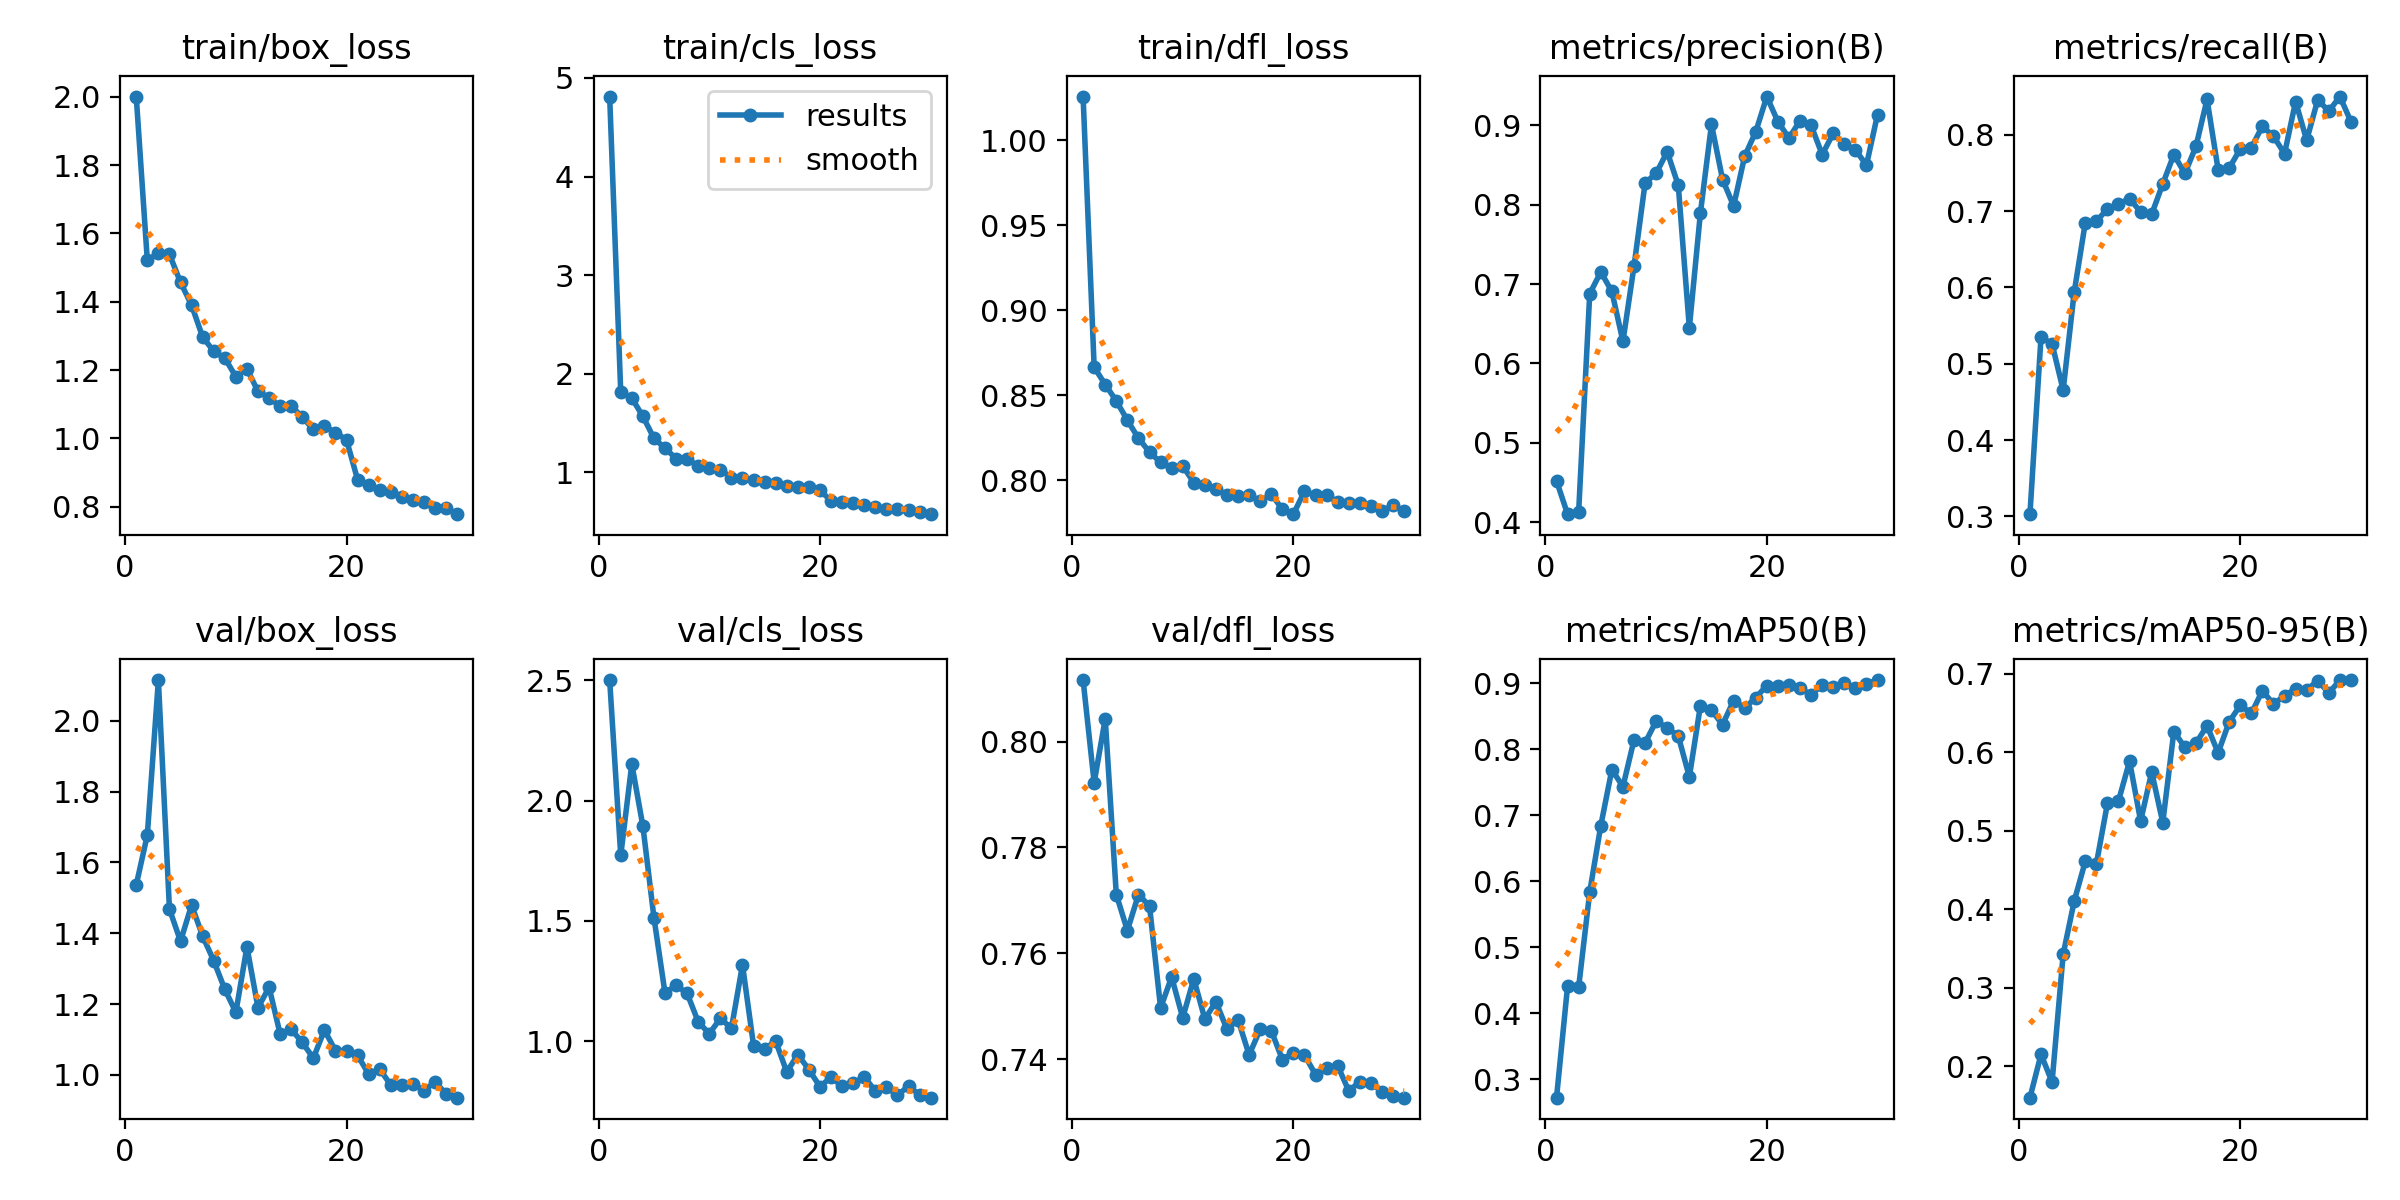

In [6]:
best_model = YOLO(str(best_weights))

def print_metrics(metrics, split_label):
    print(f"\n{split_label} mAP50:    {metrics.box.map50:.4f}")
    print(f"{split_label} mAP50-95: {metrics.box.map:.4f}")
    ap50 = metrics.box.ap50
    ap = metrics.box.ap
    ap_class_ids = metrics.box.ap_class_index
    reported = {int(cid): (ap50[idx], ap[idx]) for idx, cid in enumerate(ap_class_ids)}
    print("Per-class breakdown:")
    for cid, cname in enumerate(class_names):
        if cid in reported:
            c_ap50, c_ap = reported[cid]
            print(f"  {cid}: {cname:<24} mAP50={c_ap50:.4f}  mAP50-95={c_ap:.4f}")
        else:
            print(f"  {cid}: {cname:<24} (no metrics)")

val_metrics = best_model.val(
    data=str(DATA_YAML_PATH), split="val", imgsz=IMG_SIZE, device=DEVICE, plots=True
)
print_metrics(val_metrics, "Validation")

if "test" in data_config:
    test_metrics = best_model.val(
        data=str(DATA_YAML_PATH), split="test", imgsz=IMG_SIZE, device=DEVICE, plots=True
    )
    print_metrics(test_metrics, "Held-out Test")

results_plot = run_dir / "results.png"
if results_plot.is_file():
    display(Image.open(results_plot))

## 6. Visual Inference Preview

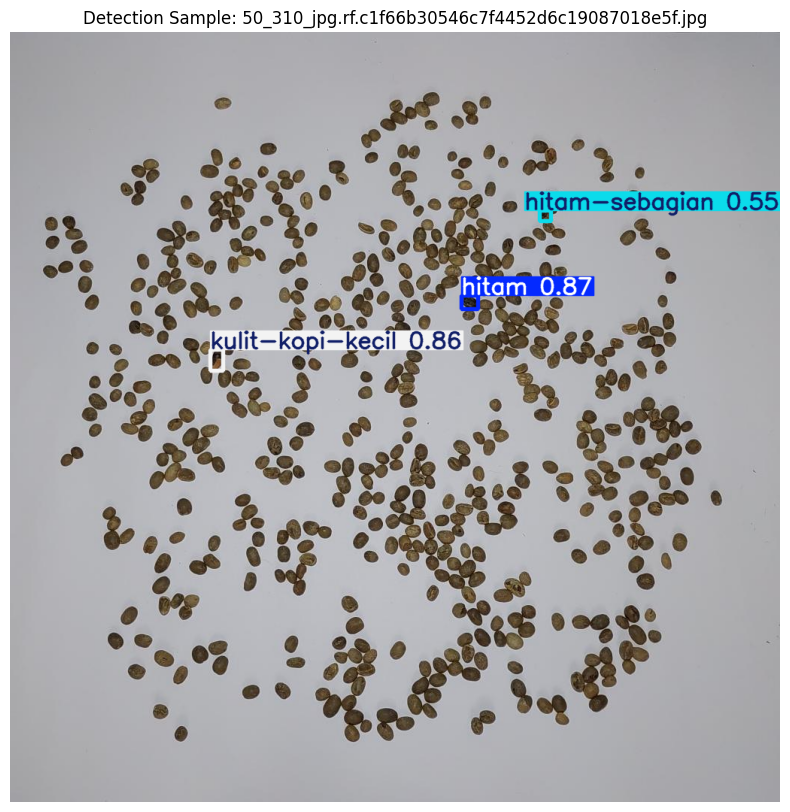

In [7]:
if split_images.get("val"):
    sample_path = split_images["val"][0]
    pred = best_model.predict(source=str(sample_path), conf=0.25, imgsz=IMG_SIZE, device=DEVICE, verbose=False)[0]
    plt.figure(figsize=(10, 10))
    plt.imshow(pred.plot()[..., ::-1])
    plt.axis("off")
    plt.title(f"Detection Sample: {sample_path.name}")
    plt.show()

## 7. Export Weights & Microservice Config

In [8]:
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
exported_onnx = Path(best_model.export(format="onnx", imgsz=IMG_SIZE))
if not exported_onnx.is_file():
    raise FileNotFoundError(f"ONNX export failed: {exported_onnx}")

final_pt = EXPORT_DIR / "best.pt"
final_onnx = EXPORT_DIR / "best.onnx"
shutil.copy2(best_weights, final_pt)
shutil.copy2(exported_onnx, final_onnx)

class_manifest = {
    "num_classes": len(class_names),
    "names": {str(cid): cn for cid, cn in enumerate(class_names)},
    "dataset_source": DATASET_SOURCE,
    "dataset_license": DATASET_LICENSE,
    "checkpoint": MODEL_CHECKPOINT,
    "imgsz": IMG_SIZE,
}
manifest_path = EXPORT_DIR / "classes.json"
manifest_path.write_text(json.dumps(class_manifest, indent=2), encoding="utf-8")

print(f"PyTorch:  {final_pt}")
print(f"ONNX:     {final_onnx}")
print(f"Manifest: {manifest_path}")

# Microservice integration snippet
print("\nCopy this into app/services/yolo_detector.py:")
onnx_entries = [f'{i}: "{n}"' for i, n in enumerate(class_names)]
print(f'ONNX_CLASSES = {{{', '.join(onnx_entries)}}}')
map_entries = [f'"{n}": "{n.replace("-", " ").replace("_", " ").title()}"' for n in class_names]
print(f'CLASS_NAME_MAP = {{{', '.join(map_entries)}}}')

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/content/bunavision_runs/coffee_yolov8n/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (6.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 311ms
Prepared 4 packages in 523ms
Installed 4 packages in 32ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.0
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: sl

In [9]:
from google.colab import files

for artifact in (final_pt, final_onnx, manifest_path):
    files.download(str(artifact))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>